# Preprocessing: `player_standard`

Análisis y limpieza de la tabla estándar de jugadores. Rango: **2018-2025**.
Salida limpia → `data/processed/laliga_player_standard_clean.csv`.

**Decisiones de limpieza aplicadas** (detalle en cada sección):

| Tema | Decisión |
|---|---|
| Identidades partidas | "Juan Sánchez" → Juanlu Sánchez; "이강인" → Lee Kangin |
| `Nation` (5 nulos) | Corrección manual verificada (todos ESP) |
| `Born` (3 nulos) | Corrección manual verificada en Transfermarkt |
| `Age` | Parseo "22-051" → años; fallback aproximado desde `Born` |
| `Pos` → `Position` | 3 columnas: `Position_main` (lógica), `Position_sec`, `Position` (display) |
| Progresión y xG (11 filas rotas) | Lee/Guillamón 2023: imputación por ritmo per-90 (temporada **sintética**, documentado). Marginales <200 min: 0 |
| Derivadas `_Per` | Recalculadas desde bases imputadas, no imputadas aparte |
| Outliers (edad 41, Gls_Per=9…) | Datos legítimos, **no se tocan**; la protección es el filtro de minutos en el análisis |
| `Attendance`-style NaN | n/a en esta tabla |

## 0. Setup

In [97]:
import sys
from pathlib import Path

# localizar src/ subiendo niveles (robusto al cwd del kernel)
p = Path.cwd()
for _ in range(5):
    if (p / "src" / "utils.py").exists():
        sys.path.append(str(p / "src"))
        break
    p = p.parent

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import (AnalisisUnivariante, parsear_posiciones, corregir_por_jugador,
                   imputar_por_ritmo, imputar_ceros_marginales,
                   convertir_numericas_disfrazadas)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW  = p / "src/notebooks/data/raw/fbref_r"
PROC = p / "src/notebooks/data/processed"
PROC.mkdir(parents=True, exist_ok=True)

PREFIJO, TABLA = "laliga", "player_standard"
SEASON_MIN, SEASON_MAX = 2018, 2025
CLAVE = ["Season_End_Year", "Squad", "Player"]

df = pd.read_csv(RAW / f"{PREFIJO}_{TABLA}.csv")
df = df[df["Season_End_Year"].between(SEASON_MIN, SEASON_MAX)].reset_index(drop=True)
print("shape:", df.shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
shape: (4692, 38)


## 1. Exploración
Resumen global; el detalle columna a columna (`an.analizar_todo()`) se deja
comentado para no inflar el notebook — descoméntalo cuando quieras el informe completo.

In [98]:
an = AnalisisUnivariante(df, ignorar=["Url"])
display(an.resumen())
# an.analizar_todo()   # informe completo columna a columna (mucho output)

,columna,tipo_detectado,dtype,n_nulos,pct_nulos,n_unicos
0,xG_Expected,numerica,float64,11,0.2,173
1,xG+xAG_Per,numerica,float64,11,0.2,146
2,xAG_Per,numerica,float64,11,0.2,73
3,xG_Per,numerica,float64,11,0.2,118
4,PrgC_Progression,numerica,float64,11,0.2,154
5,PrgP_Progression,numerica,float64,11,0.2,261
6,xAG_Expected,numerica,float64,11,0.2,98
7,npxG+xAG_Expected,numerica,float64,11,0.2,200
8,npxG_Expected,numerica,float64,11,0.2,153
9,PrgR_Progression,numerica,float64,11,0.2,286


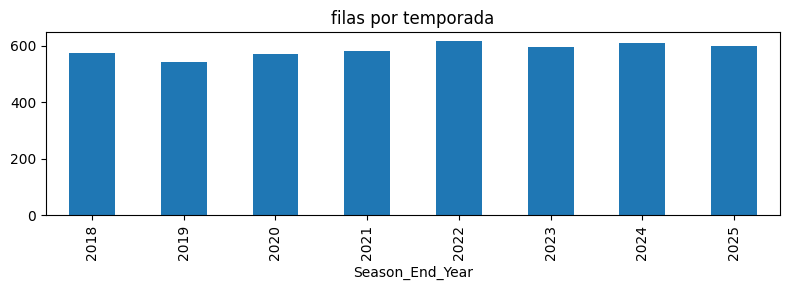

In [99]:
# cobertura temporal: 8 temporadas completas
df["Season_End_Year"].value_counts().sort_index().plot(kind="bar", figsize=(8,3), title="filas por temporada")
plt.tight_layout(); plt.show()

In [100]:
# duplicados por clave natural (traspasos de invierno crean filas legitimas por equipo)
dup = df.duplicated(subset=CLAVE).sum()
print(f"duplicados exactos por {CLAVE}: {dup}")
multi = df.groupby(["Player","Season_End_Year"])["Squad"].nunique()
print(f"jugador-temporadas con 2+ equipos (traspasos, legitimo): {(multi > 1).sum()}")

duplicados exactos por ['Season_End_Year', 'Squad', 'Player']: 0
jugador-temporadas con 2+ equipos (traspasos, legitimo): 119


## 2. Limpieza
Todo sobre `clean`, en orden de dependencia: tipos → identidades → nulos →
derivadas. **El orden importa**: las identidades van antes que las imputaciones
(la imputación por ritmo necesita la carrera unificada).

In [101]:
clean = df.copy()

# 2.0 numericas disfrazadas de texto
convertidas = convertir_numericas_disfrazadas(
    clean, excluir=("Squad","Comp","Player","Nation","Pos","Age","Url"))
print("convertidas a numerico:", convertidas or "ninguna")

convertidas a numerico: ninguna


### 2.1 Identidades partidas
Dos jugadores con la carrera dividida en dos nombres (rompe el modo carrera del buscador):
- **"Juan Sánchez"** (Sevilla 2022, debut, Born=2003) = **Juanlu Sánchez** — verificado por club+año+edad.
- **"이강인"** (Mallorca 2023) = **Lee Kangin** — grafía coreana en una sola temporada; se unifica a la grafía dominante en nuestros datos.

In [102]:
mask_juanlu = (clean["Player"] == "Juan Sánchez") & (clean["Squad"] == "Sevilla") & (clean["Born"] == 2003)
clean.loc[mask_juanlu, "Player"] = "Juanlu Sánchez"

clean.loc[clean["Player"].isin(["이강인", "Kang-in Lee"]), "Player"] = "Lee Kangin"

# verificacion: carreras unificadas
display(clean[clean["Player"].isin(["Juanlu Sánchez", "Lee Kangin"])]
        [["Player", "Squad", "Season_End_Year", "Min_Playing"]].sort_values(["Player","Season_End_Year"]))

,Player,Squad,Season_End_Year,Min_Playing
2819,Juanlu Sánchez,Sevilla,2022,5
4023,Juanlu Sánchez,Sevilla,2024,1181
4587,Juanlu Sánchez,Sevilla,2025,1722
1046,Lee Kangin,Valencia,2019,24
1619,Lee Kangin,Valencia,2020,454
2191,Lee Kangin,Valencia,2021,1262
2649,Lee Kangin,Mallorca,2022,1411
3240,Lee Kangin,Mallorca,2023,2823


### 2.2 `Nation` — 5 nulos
Fichas incompletas en FBref; verificados a mano, todos españoles (Guillamón es
incluso internacional absoluto).

In [103]:
NATION_FIX = {
    "Blanco": "ESP",           # Cadiz 2023
    "Hugo Guillamón": "ESP",   # Valencia 2023
    "Santiago García": "ESP",  # Getafe 2024
    "Pablo Saenz": "ESP",      # Granada 2024
    "Fer López": "ESP",        # Celta Vigo 2025
}
n = corregir_por_jugador(clean, "Nation", NATION_FIX)
print("Nation corregidos:", n)
assert clean["Nation"].isna().sum() == 0

Nation corregidos: 5


### 2.3 `Born` — 3 nulos y `Age`
`Age` deriva de `Born`, por eso fallan juntos. Años verificados a mano en Transfermarkt.
`Age_years`: parseo de "22-051" (años-días) con fallback aproximado desde `Born`
(±1 año en el peor caso; solo afecta a marginales).

In [104]:
BORN_FIX = {
    "Pablo Saenz": 2003,     # verificados en Transfermarkt
    "Max Svensson": 2001,
    "Fer López": 2004,
}
print("Born corregidos:", corregir_por_jugador(clean, "Born", BORN_FIX))

clean["Age_years"] = pd.to_numeric(clean["Age"].astype(str).str.split("-").str[0], errors="coerce")
sin_age = clean["Age_years"].isna() & clean["Born"].notna()
clean.loc[sin_age, "Age_years"] = clean.loc[sin_age, "Season_End_Year"] - clean.loc[sin_age, "Born"] - 1
clean = clean.drop('Age', axis=1)
print("Age_years imputadas desde Born:", int(sin_age.sum()))
assert clean["Age_years"].isna().sum() == 0

# outliers de edad (39-41): Joaquin y porteros veteranos -> datos legitimos, no se tocan

Born corregidos: 3
Age_years imputadas desde Born: 3


### 2.4 `Pos` → `Position`
1 nulo (Juanlu Sánchez 2022, 5 min) → DF (su posición natural; imputación de
impacto nulo, no pasa el filtro de minutos). Después, parseo a 3 columnas legibles.

In [105]:
clean.loc[(clean["Player"] == "Juanlu Sánchez") & (clean["Pos"].isna()), "Pos"] = "DF"
assert clean["Pos"].isna().sum() == 0

clean[["Position_main", "Position_sec", "Position"]] = parsear_posiciones(clean["Pos"])
clean = clean.drop(columns=["Pos"])
print(clean["Position"].value_counts())

Position
Defender                 1388
Midfielder               1007
Forward                   639
Forward / Midfielder      467
Midfielder / Forward      460
Goalkeeper                357
Defender / Midfielder     154
Midfielder / Defender     126
Defender / Forward         64
Forward / Defender         30
Name: count, dtype: int64


### 2.5 Coherencia interna
Chequeos entre columnas hermanas: si pasan, `MP/Starts/Min` y la familia goleadora
quedan validadas en bloque.

In [106]:
assert (clean["Starts_Playing"] <= clean["MP_Playing"]).all(), "titularidades > partidos"
assert (clean["Min_Playing"] <= clean["MP_Playing"] * 90 + 60).all(), "minutos imposibles"
assert (clean["G_minus_PK"] <= clean["Gls"]).all(), "goles sin penalti > goles"
assert (clean["PK"] <= clean["PKatt"]).all(), "PK > PKatt"
assert (clean["G_minus_PK"] == clean["Gls"] - clean["PK"]).all(), "G_minus_PK != Gls - PK"
print("coherencia interna OK")

coherencia interna OK


### 2.6 Progresión y familia xG — 11 fichas rotas
Las mismas 11 filas tienen NaN en PrgC/PrgP/PrgR y en toda la familia xG
(verificado: también rotas en las tablas shooting/passing → no hay dato real
que recuperar). Tratamiento en dos niveles:
- **Lee Kangin y Hugo Guillamón (2023, minutos relevantes)**: imputación por
  ritmo per-90 de sus otras temporadas. ⚠️ Su temporada 2023 queda **sintética**
  (estimada, probablemente algo infravalorada — 2023 fue el mejor año de Lee).
- **9 marginales (<200 min)**: NaN = "sin registros" → 0. Sin impacto: ninguno
  pasa el filtro de 900 min del análisis.

In [107]:
prog_cols = ["PrgC_Progression", "PrgP_Progression", "PrgR_Progression"]
xg_cols   = ["xG_Expected", "npxG_Expected", "xAG_Expected", "npxG+xAG_Expected"]

for jugador in ["Lee Kangin", "Hugo Guillamón"]:
    imputar_por_ritmo(clean, jugador, 2023, prog_cols)
    imputar_por_ritmo(clean, jugador, 2023, xg_cols)

print("a 0 (progresion):", imputar_ceros_marginales(clean, prog_cols))
print("a 0 (xG):", imputar_ceros_marginales(clean, xg_cols))

[imputar_por_ritmo] Lee Kangin 2023: {'PrgC_Progression': np.float64(71.3), 'PrgP_Progression': np.float64(135.8), 'PrgR_Progression': np.float64(131.9)} (ref: 3 temporadas, 31.4 noventas)
[imputar_por_ritmo] Lee Kangin 2023: {'xG_Expected': np.float64(3.7), 'npxG_Expected': np.float64(3.7), 'xAG_Expected': np.float64(4.1), 'npxG+xAG_Expected': np.float64(7.8)} (ref: 3 temporadas, 31.4 noventas)
[imputar_por_ritmo] Hugo Guillamón 2023: {'PrgC_Progression': np.float64(10.7), 'PrgP_Progression': np.float64(79.6), 'PrgR_Progression': np.float64(8.2)} (ref: 4 temporadas, 18.1 noventas)
[imputar_por_ritmo] Hugo Guillamón 2023: {'xG_Expected': np.float64(0.3), 'npxG_Expected': np.float64(0.3), 'xAG_Expected': np.float64(0.2), 'npxG+xAG_Expected': np.float64(0.5)} (ref: 4 temporadas, 18.1 noventas)
a 0 (progresion): 9
a 0 (xG): 9


### 2.7 Derivadas `_Per` (por 90)
No se imputan aparte: se **recalculan** desde las bases ya imputadas para
mantener la consistencia. Los outliers extremos (Gls_Per=9 de un suplente con
10 min) son ratios correctos de muestras diminutas — no se tocan; la protección
es el filtro de minutos en el análisis.

In [108]:
n90 = clean["Mins_Per_90_Playing"].replace(0, np.nan)

clean["Gls_Per"]       = clean["Gls_Per"].fillna((clean["Gls"] / n90).round(2))
clean["Ast_Per"]       = clean["Ast_Per"].fillna((clean["Ast"] / n90).round(2))
clean["G+A_Per"]       = clean["G+A_Per"].fillna((clean["G+A"] / n90).round(2))
clean["G_minus_PK_Per"] = clean["G_minus_PK_Per"].fillna((clean["G_minus_PK"] / n90).round(2))
clean["G+A_minus_PK_Per"] = clean["G+A_minus_PK_Per"].fillna(((clean["G+A"] - clean["PK"]) / n90).round(2))
clean["xG_Per"]        = clean["xG_Per"].fillna((clean["xG_Expected"] / n90).round(2))
clean["npxG_Per"]      = clean["npxG_Per"].fillna((clean["npxG_Expected"] / n90).round(2))
clean["xAG_Per"]       = clean["xAG_Per"].fillna((clean["xAG_Expected"] / n90).round(2))
clean["xG+xAG_Per"]    = clean["xG+xAG_Per"].fillna(((clean["xG_Expected"] + clean["xAG_Expected"]) / n90).round(2))
clean["npxG+xAG_Per"]  = clean["npxG+xAG_Per"].fillna((clean["npxG+xAG_Expected"] / n90).round(2))

## 3. Verificación final
Cero nulos en todo el DataFrame (salvo `Position_sec`, que es NA por diseño
para jugadores de una sola posición).

In [109]:
nulos = clean.isna().sum()
nulos = nulos[nulos > 0].drop("Position_sec", errors="ignore")
assert nulos.empty, f"quedan nulos:\n{nulos}"
print(f"OK: {clean.shape[0]} filas x {clean.shape[1]} cols, sin nulos inesperados")

OK: 4692 filas x 40 cols, sin nulos inesperados


## 4. Export

In [110]:
out = PROC / f"{PREFIJO}_{TABLA}_clean.csv"
clean.to_csv(out, index=False)
print("guardado:", out, f"({len(clean)} filas)")

guardado: c:\Users\daniel.cejas\Projects\football-project\src\notebooks\data\processed\laliga_player_standard_clean.csv (4692 filas)
